In questo codice testo l'algoritmo di Nikolson per una condizione al bordo di cui è nota la g(t) risultante

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import lu_factor, lu_solve

np.random.seed(42)

In [ ]:
import matplotlib as mpl

# ---- STILE PAPER ----
mpl.rcParams.update({

    # Usa font LaTeX (coerente con paper)
    "text.usetex": True,
    "font.family": "serif",
    "font.serif": ["Computer Modern Roman"],

    # Dimensioni testo (standard journal)
    "font.size": 9,
    "axes.titlesize": 9,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,

    # Spessori ottimizzati per stampa
    "lines.linewidth": 1.2,
    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,

    # Tick dentro (stile PRL/JCP)
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Griglia molto leggera
    "grid.linestyle": ":",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,

    # Legenda minimale
    "legend.frameon": False,
})

Time scale coeff:  250.0
dx:  0.01
dt:  0.05
r:  0.5
Slope (m): -3.9640201893750155e-11
Intercept (b): 0.9999999999978176
Expected Slope (m): 0.0
Slope (m): -0.6666666666668369
Intercept (b): 0.999999999999974
Expected Slope (m): -0.6666666666666666
Slope (m): -1.4285714285714755
Intercept (b): 0.9999999999999749
Expected Slope (m): -1.4285714285714286
Slope (m): -1.6666666666666883
Intercept (b): 0.9999999999999799
Expected Slope (m): -1.6666666666666667
Slope (m): -1.8181818181818181
Intercept (b): 0.9999999999999779
Expected Slope (m): -1.8181818181818181


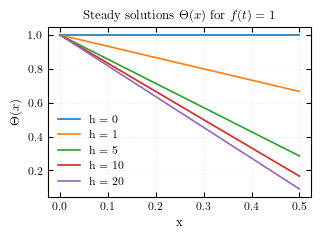

In [ ]:
L = 0.5
Tf = 2500
nt = 50000

D = 0.001

#dx = L/(nx-1)
dt = Tf/nt

wanted_r = 0.5

dx = np.sqrt(D*dt/wanted_r)
nx = int(L/dx) + 1
dx = L/(nx-1)     

r = D*dt/(dx**2)

print("Time scale coeff: ", L*L/D)
print("dx: ", dx)
print("dt: ", dt)
print("r: ", r)

plt.figure(figsize=(3.4, 2.2))

x_array = np.linspace(0, L, nx)
t_array = np.linspace(0,Tf,nt)

for h in [0,1,5,10,20]:

    A = np.zeros((nx, nx))
    B = np.zeros((nx, nx))

    # Nodi interni
    for i in range(1, nx-1):
        A[i, i-1] = -r/2
        A[i, i]   = 1 + r
        A[i, i+1] = -r/2

        B[i, i-1] = r/2
        B[i, i]   = 1 - r
        B[i, i+1] = r/2

    # Boundary sinistra (Dirichlet)
    A[0,0] = 1
    #B[0,0] = 1
    B[0,:] = 0
    
    # Boundary destra (Robin)
    A[-1, -2] = -2*r
    A[-1, -1] = 1 + 2*r*(1+h*dx)

    B[-1, -2] = 2*r
    B[-1, -1] = 1 - 2*r*(1+h*dx)

    lu, piv = lu_factor(A)

    T = np.zeros(shape=(nx,nt))

    # Initial condition
    T[:,0] = 0

    # Right boundary 
    f = 1
    T[0,0] = f

    for n in range(1,nt):
        b = B @ T[:,n-1]
        b[0] = f # impongo dirichlet
        T[:,n] = lu_solve((lu, piv), b)

    # Fit lineare
    m, b_fit = np.polyfit(x_array, T[:,-1], 1)

    print("Slope (m):", m)
    print("Intercept (b):", b_fit)
    print(f"Expected Slope (m): {-h/(1+h*L)}")

    plt.plot(x_array, m*x_array+b_fit, label=f"h = {h}")

plt.legend()
plt.title(r"Steady solutions $\Theta(x)$ for $f(t) = 1$")
plt.xlabel("x")
plt.ylabel(r"$\Theta(x)$")
plt.grid()
plt.tight_layout()
plt.savefig("assets/soluzione_lineare_nikolson.pdf")
plt.show()